# From lab data to process simulation

Imagine you have two files on your desk:

* **your kinetics** as an [EnzymeML](https://enzymeml.org) document, straight from the lab, and
* **your flowsheet** as a [DEXPI](https://dexpi.org) process model, straight from a flowsheeting tool.

Go ahead and simulate; the rest is simple. In this tutorial, BioSTEAM reads both files, connects them, and gives you a running process model in five steps:

1. Read the kinetics
2. Resolve the chemicals
3. Load the flowsheet
4. Connect kinetics and reactor
5. Simulate, explore, and share

The example is the regeneration of the cofactor NADH by formate dehydrogenase (FDH) in a continuous stirred tank reactor:

$$\text{Formate} + \text{NAD}^+ \xrightarrow{\text{FDH}} \text{CO}_2 + \text{NADH}$$

Nothing needs to be installed besides BioSTEAM.

## Setup

Both example files ship with BioSTEAM. **To use your own data, point these two paths to your files**; everything below stays the same.

In [1]:
import warnings
import biosteam as bst
from biosteam.interop import chemicals, dexpi, enzymeml, examples

kinetics_file = examples.FDH_ENZYMEML   # EnzymeML document (.json)
flowsheet_file = examples.FDH_DEXPI     # DEXPI process model (.xml)

bst.main_flowsheet.set_flowsheet('nadh_regeneration')
bst.nbtutorial()  # Light-weight displays for notebooks

# The reactor of this small example is below the size range of the
# vessel cost correlations; silence the reminder.
warnings.simplefilter('ignore', bst.exceptions.CostWarning)

## 1. Read the kinetics

An EnzymeML document records what the lab found: the species, the reaction, a rate law, and the fitted parameters with their units.

In [2]:
document = enzymeml.read(kinetics_file)
reaction = document.get_reaction()

print(document.name)
print()
print('Species:  ', ', '.join(document.species))
print('Reaction: ', reaction.stoichiometry)
print('Enzyme:   ', reaction.modifiers)
print('Measured at', document.temperature, 'K and pH', document.pH)

NADH regeneration by formate dehydrogenase (reference case)

Species:   formate, nad, co2, nadh, fdh
Reaction:  {'formate': -1.0, 'nad': -1.0, 'co2': 1.0, 'nadh': 1.0}
Enzyme:    {'fdh': 'biocatalyst'}
Measured at 303.15 K and pH 7.5


In [3]:
print(reaction.rate_law.replace(' / ', '\n    / '))
print()
for parameter in document.parameters.values():
    print(f'{parameter.symbol:12} = {parameter.value:<6g} {parameter.unit_name}')

kcat * fdh * nad * formate
    / (K_i_nad * K_m_formate + K_m_formate * nad + K_m_nad * formate + nad * formate)

kcat         = 3.7    1 / s
K_m_formate  = 5.6    mmol / l
K_m_nad      = 0.045  mmol / l
K_i_nad      = 0.04   mmol / l


The rate law is an ordered bi-bi mechanism in its initial-rate form. You never need to convert units yourself: BioSTEAM reads the unit of every parameter from the document.

<div class="alert alert-info">

**Note:** The parameters of this example document are representative values for illustration, not a curated measurement.

</div>

## 2. Resolve the chemicals

The document identifies its species by InChIKey and ChEBI number. BioSTEAM looks them up in its chemical databases. Two species are not in there, so we state what we know about them: the formula of NADH and the molecular weight of the enzyme.

In [4]:
properties = {
    'nadh': {'formula': 'C21H29N7O14P2'},
    'fdh': {'MW': 40400.},  # g/mol, approximate
}
with warnings.catch_warnings():
    # NAD+ is found, but without property models; see the note below.
    warnings.simplefilter('ignore', chemicals.PlaceholderWarning)
    process_chemicals = document.create_chemicals(properties=properties)

bst.settings.set_thermo(process_chemicals)
for chemical in process_chemicals:
    source = 'database' if chemical.CAS != chemical.ID else 'your data'
    print(f'{chemical.ID:8} {chemical.MW:10.2f} g/mol   from {source}')

Water         18.02 g/mol   from database
formate       46.03 g/mol   from database
nad          663.43 g/mol   from database
co2           44.01 g/mol   from database
nadh         665.44 g/mol   from your data
fdh        40400.00 g/mol   from your data


<div class="alert alert-info">

**Note:** Properties that no source provides (such as the heat capacity of NAD<sup>+</sup>) default to those of water, and BioSTEAM warns about each one unless you silence the warning as above. Mass balances are exact; read energy balances for such dilute species as estimates.

</div>

## 3. Load the flowsheet

The DEXPI file describes the process topology: a feed tank, a pump, a reactor and a product tank, connected by streams. It was not written by BioSTEAM and knows nothing about kinetics.

In [5]:
with warnings.catch_warnings(record=True) as notes:
    warnings.simplefilter('always', dexpi.DexpiWarning)
    process = bst.System.from_dexpi(flowsheet_file)

for note in notes:
    print('Note:', note.message)

Note: reactor 'R1' has no BioSTEAM annotation; it is created without reactions and with a residence time of 1 hr


BioSTEAM tells you what the file left open: the reactor has no reactions and no residence time yet. That is exactly what the lab data will fill in.

Each DEXPI process step became the matching BioSTEAM unit operation, and the feed arrived with its composition and conditions, converted from the units used in the file (°C, bar, kmol/s):

In [6]:
for unit in process.units:
    print(f'{unit.ID}: {type(unit).__name__}')

P1: Pump
R1: SinglePhaseReactor


In [7]:
feed = process.flowsheet.stream.feed
feed.show(flow='mol/hr', N=6)

Stream: feed to <Pump: P1>
phase: 'l', T: 298.15 K, P: 101325 Pa
flow (mol/hr): Water    5.54e+04
               formate  101
               nad      5.04
               fdh      0.000198


## 4. Connect kinetics and reactor

One line assigns the reaction from the EnzymeML document to the reactor. The residence time is your design choice.

In [8]:
reactor = process.flowsheet.unit.R1
document.parameterize(reactor)
reactor.tau = 2.  # Residence time [hr]
reactor.reactions.show()

Reaction (by mol):
stoichiometry                reactant
formate + nad -> co2 + nadh  formate


The reaction has no fixed conversion. Instead, BioSTEAM solves the steady-state balance of an ideal stirred tank, in which the reaction runs at outlet concentrations:

$$\xi = r(C_\text{out}) \cdot V \qquad \text{with} \qquad V = \tau \, Q$$

Here $\xi$ is the amount converted per hour, $r$ the rate law, $\tau$ the residence time and $Q$ the volumetric flow.

## 5. Simulate, explore, and share

### Simulate

In [9]:
process.simulate()
product = process.flowsheet.stream.product

def conversion():
    return 1 - product.imol['nad'] / feed.imol['nad']

print(f'NAD+ conversion:  {conversion():.1%}')
print(f'NADH produced:    {product.imol["nadh"] * 1e3:.2f} mol/hr')
print(f'Reactor volume:   {reactor.design_results["Reactor volume"]:.2f} m3')
print(f'Installed cost:   {process.installed_equipment_cost / 1e3:.0f} thousand USD')

NAD+ conversion:  90.4%
NADH produced:    4.56 mol/hr
Reactor volume:   2.52 m3
Installed cost:   125 thousand USD


In [10]:
product.show(flow='mol/hr', N=6)

Stream: product from <SinglePhaseReactor: R1>
phase: 'l', T: 303.15 K, P: 200000 Pa
flow (mol/hr): Water    5.54e+04
               formate  96.2
               nad      0.484
               co2      4.56
               nadh     4.56
               fdh      0.000198


### Explore

The kinetics follow the reactor: change the residence time or the enzyme loading and simulate again. How much reactor and how much enzyme does a given conversion need?

In [11]:
import numpy as np

residence_times = np.linspace(0.25, 6., 24)  # hr
enzyme_loadings = [0.5, 1., 2.]              # relative to the base case
base_enzyme = feed.imol['fdh']

curves = {}
for loading in enzyme_loadings:
    feed.imol['fdh'] = loading * base_enzyme
    curve = []
    for tau in residence_times:
        reactor.tau = tau
        process.simulate()
        curve.append(conversion())
    curves[loading] = curve

# Back to the base case
feed.imol['fdh'] = base_enzyme
reactor.tau = 2.
process.simulate()

for loading, curve in curves.items():
    print(f'{loading:g}x enzyme: {curve[0]:.0%} at {residence_times[0]:g} hr, '
          f'{curve[-1]:.0%} at {residence_times[-1]:g} hr')

0.5x enzyme: 6% at 0.25 hr, 98% at 6 hr
1x enzyme: 12% at 0.25 hr, 100% at 6 hr
2x enzyme: 24% at 0.25 hr, 100% at 6 hr


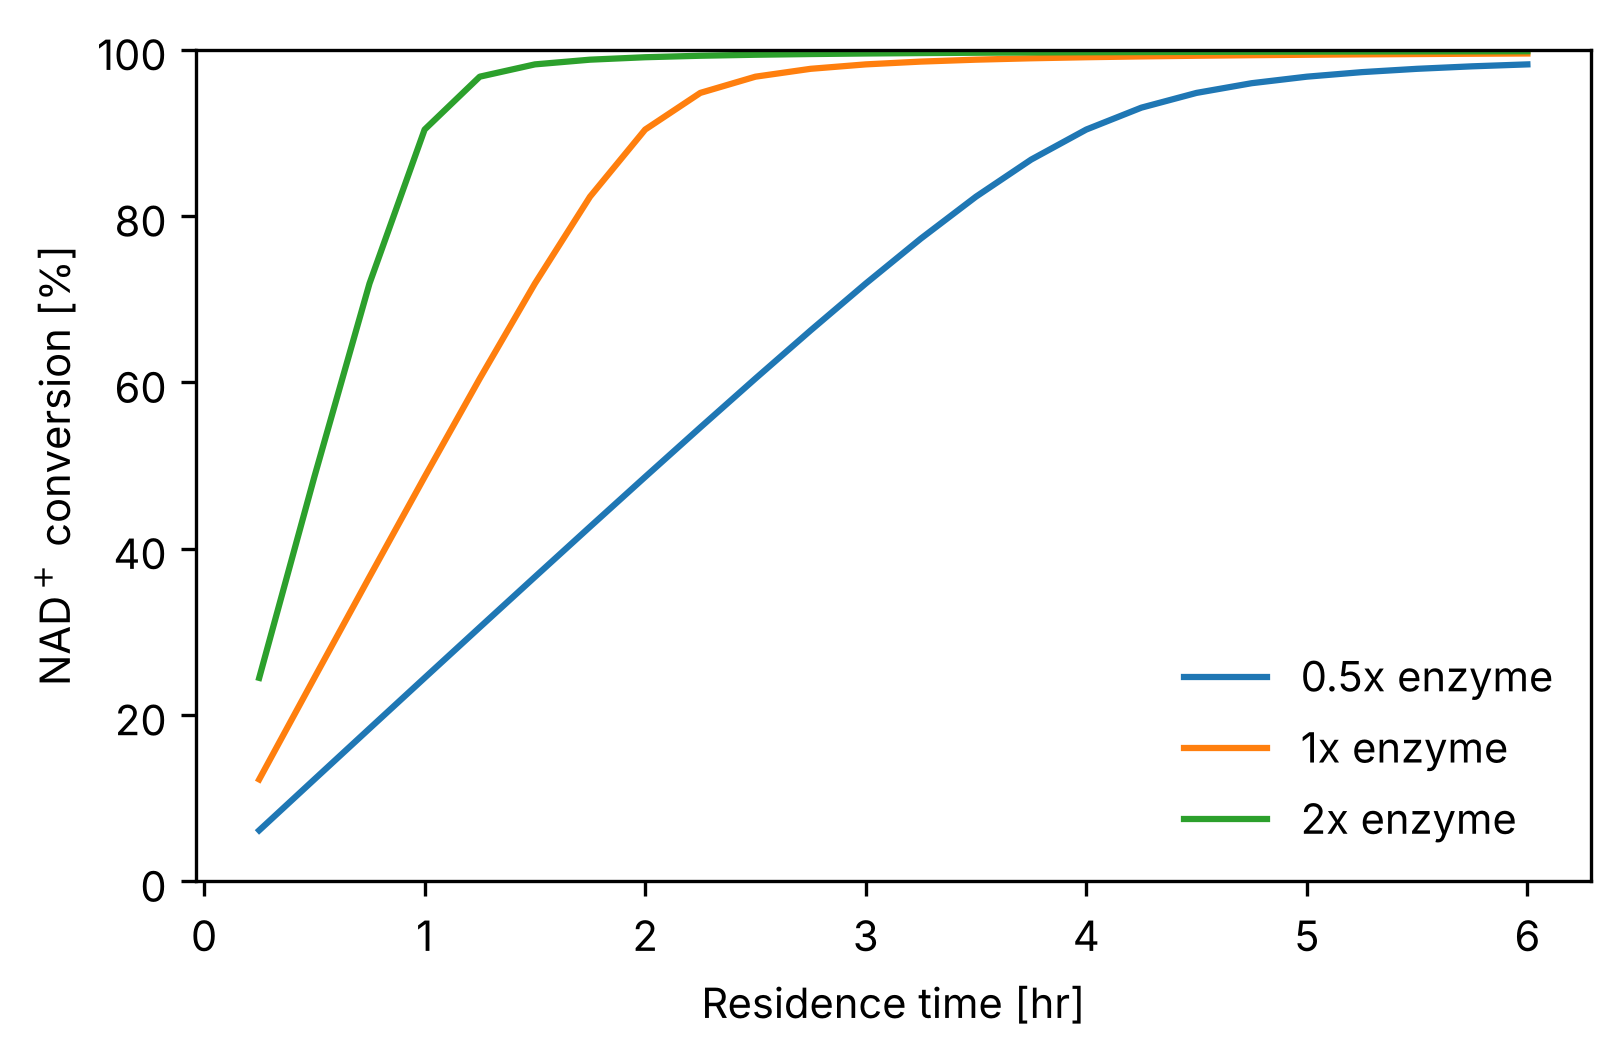

In [12]:
# NBVAL_IGNORE_OUTPUT
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.6))
for loading, curve in curves.items():
    ax.plot(residence_times, 100 * np.array(curve), label=f'{loading:g}x enzyme')
ax.set_xlabel('Residence time [hr]')
ax.set_ylabel('NAD$^+$ conversion [%]')
ax.set_ylim(0, 100)
ax.legend(frameon=False)
plt.show()

### Update the kinetics

When the lab sends a new EnzymeML document, read it and parameterize the reactor again. As a stand-in for new data, suppose an improved enzyme variant with twice the turnover number:

In [13]:
import json

with open(kinetics_file, encoding='utf-8') as file:
    new_data = json.load(file)
for parameter in new_data['parameters']:
    if parameter['id'] == 'kcat':
        parameter['value'] *= 2

before = conversion()
enzymeml.read(new_data).parameterize(reactor)
process.simulate()
print(f'NAD+ conversion: {before:.1%} -> {conversion():.1%}')

# Back to the original kinetics
document.parameterize(reactor)
process.simulate()

NAD+ conversion: 90.4% -> 99.1%


### Share

Export the model as DEXPI again. The file now carries the simulated stream results in standard DEXPI attributes, readable by any DEXPI tool, and the BioSTEAM-specific settings (residence time, kinetics and their EnzymeML provenance) in standard DEXPI notes.

In [14]:
import os
import tempfile

shared_file = os.path.join(tempfile.mkdtemp(), 'nadh_regeneration_simulated.xml')
process.to_dexpi(shared_file)

colleague = bst.System.from_dexpi(shared_file, flowsheet='colleague')
colleague.simulate()
product_copy = colleague.flowsheet.stream.product
print('Kinetics came along:', colleague.flowsheet.unit.R1.reactions.rate)
print('Same result:', bool(np.allclose(product_copy.mol, product.mol, rtol=1e-9)))

Kinetics came along: SteadyStateCSTRRate('kcat * fdh * nad * formate / (K_i_nad * K_m_formate + K_m_formate * nad + K_m_nad * formate + nad * formate)')
Same result: True


## Using your own files

A short checklist:

* **Matching names.** The component identifiers in the DEXPI file must equal the species ids in the EnzymeML document (here `formate`, `nad`, `co2`, `nadh`, `fdh`, plus `Water`). If they differ, rename the species with `document.with_chemical_IDs({'s0': 'formate', ...})`.
* **Unknown chemicals.** Give the formula or molecular weight of species that databases do not know through `properties`, as in step 2. Add `online=True` to also query PubChem (this sends identifiers to an external service).
* **EnzymeML formats.** JSON documents work out of the box. OMEX archives need the optional `pyenzyme` package (`pip install biosteam[enzymeml]`).
* **Units.** Units in both files are converted for you. The rate law must give a rate in concentration per time.
* **Other unit operations.** Pumps, heat exchangers, mixers, splitters, flashes, tanks and valves are mapped as well. A process step that BioSTEAM has no model for becomes a pass-through placeholder, so the flowsheet always loads; register your own unit class with `dexpi.default_registry.register`.

See the [interop API reference](../API/interop/index.txt) for details.